# Praktikum Data Mining: Association Rule Mining (Market Basket Analysis)
## Notebook 2: Tugas Praktikum (Tugas 1 sampai Tugas 4)
Nama: AUDITYA MEROSYA PUTRI | NIM: 24343001 

Nama: Muhammad Zahran       | NIM: 24343077

Nama: Muhammad Riyad Anwari | NIM: 24343044


In [1]:
# Instal mlxtend bila belum tersedia (di Google Colab: jalankan sel ini sekali)
try:
    import mlxtend
except ImportError:
    get_ipython().system('pip install mlxtend -q')
    import mlxtend
print('mlxtend versi', mlxtend.__version__)

mlxtend versi 0.25.0


**Analisis:**
Memeriksa ketersediaan library mlxtend yang diperlukan dalam proses analisis data menggunakan algoritma Apriori. Jika library belum tersedia, program akan menginstalnya secara otomatis menggunakan perintah pip install mlxtend.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# memuat transaksi dari CSV (kolom TID dan Items; item dipisah koma)
raw = pd.read_csv('transactions_arm_praktikum.csv')
transactions = [[i.strip() for i in s.split(',')] for s in raw['Items']]

te = TransactionEncoder()
df = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

def fmt(himpunan):
    return ', '.join(sorted(himpunan))

def buat_aturan(df_onehot, min_sup, min_conf, urut='lift'):
    # Apriori + association_rules; mengembalikan (frequent itemset, aturan) dengan kolom 'aturan' yang mudah dibaca
    fi = apriori(df_onehot, min_support=min_sup, use_colnames=True)
    try:
        r = association_rules(fi, metric='confidence', min_threshold=min_conf)
    except ValueError:                       # tidak ada itemset berukuran >= 2
        r = pd.DataFrame(columns=['antecedents', 'consequents', 'support', 'confidence', 'lift'])
    if len(r):
        r = r.copy()
        r['aturan'] = r['antecedents'].map(fmt) + ' -> ' + r['consequents'].map(fmt)
        r = r.sort_values(urut, ascending=False).reset_index(drop=True)
    return fi, r

**Analisis:**
Pustaka diimpor, data transaksi dibaca dari CSV lalu diubah ke tabel one-hot. Dibuat pula fungsi buat_aturan yang menjalankan Apriori dan pembentukan aturan sekaligus agar dapat dipakai berulang pada tiap tugas.


In [3]:
print('Data siap:', df.shape, '| transaksi:', len(transactions))

Data siap: (60, 12) | transaksi: 60


# TUGAS 1: Eksplorasi Ambang Batas min_support dan min_confidence

### 1.1 min_support = 0.10 vs 0.15 (min_confidence = 0.5)

In [4]:
fi15, r15 = buat_aturan(df, 0.15, 0.5)
fi10, r10 = buat_aturan(df, 0.10, 0.5)

print(pd.DataFrame({'min_support': [0.15, 0.10], 'Frequent itemset': [len(fi15), len(fi10)], 'Aturan': [len(r15), len(r10)]}).to_string(index=False))

itemset_baru = set(map(frozenset, fi10['itemsets'])) - set(map(frozenset, fi15['itemsets']))
print('\nItemset yang muncul hanya pada min_support = 0.10:')
for s in itemset_baru:
    sup = fi10[fi10['itemsets'] == s]['support'].iloc[0]
    print('  ', sorted(s), f'(support = {sup:.3f}, {int(round(sup*len(df)))} transaksi)')

aturan_baru = r10[~r10['aturan'].isin(r15['aturan'])]
print('\nAturan yang muncul hanya pada min_support = 0.10:')
print(aturan_baru[['aturan', 'support', 'confidence', 'lift']].round(3).to_string(index=False))

 min_support  Frequent itemset  Aturan
        0.15                17      18
        0.10                19      20

Itemset yang muncul hanya pada min_support = 0.10:
   ['Gula', 'Kopi'] (support = 0.133, 8 transaksi)
   ['Keju'] (support = 0.100, 6 transaksi)

Aturan yang muncul hanya pada min_support = 0.10:
      aturan  support  confidence  lift
Gula -> Kopi    0.133       0.571 2.637
Kopi -> Gula    0.133       0.615 2.637


**Analisis 1.1:** menurunkan `min_support` dari 0,15 menjadi 0,10 menambah itemset dari 17 menjadi 19 dan aturan dari 18 menjadi 20. Tambahannya hanya dua itemset, yaitu {Keju} (6 transaksi) dan {Gula, Kopi} (8 transaksi), serta dua aturan baru, yaitu Gula → Kopi dan Kopi → Gula (confidence 0,571 dan 0,615; Lift 2,637). Keduanya masuk akal secara bisnis (pasangan minuman), tetapi didukung hanya 8 dari 60 transaksi (13,3%), di bawah batas 9 transaksi pada ambang 0,15, sehingga lebih rapuh dan lebih mudah terjadi karena kebetulan daripada aturan lain.

### 1.2 min_confidence dinaikkan menjadi 0.7 (min_support = 0.15)

In [5]:
fi_, r_semua = buat_aturan(df, 0.15, 0.5)
r_07 = r_semua[r_semua['confidence'] >= 0.7]
gugur = r_semua[r_semua['confidence'] < 0.7].sort_values('confidence', ascending=False)

print(f'Aturan awal (min_confidence 0.5): {len(r_semua)} | masih lolos pada 0.7: {len(r_07)} | gugur: {len(gugur)}')
print('\nAturan yang MASIH LOLOS (confidence >= 0.7):')
print(r_07[['aturan', 'support', 'confidence', 'lift']].round(3).to_string(index=False))
print('\nAturan yang GUGUR (confidence < 0.7):')
print(gugur[['aturan', 'support', 'confidence', 'lift']].round(3).to_string(index=False))

Aturan awal (min_confidence 0.5): 18 | masih lolos pada 0.7: 7 | gugur: 11

Aturan yang MASIH LOLOS (confidence >= 0.7):
               aturan  support  confidence  lift
Mentega, Susu -> Roti    0.183       1.000 3.333
Roti, Susu -> Mentega    0.183       0.846 2.986
Mentega, Roti -> Susu    0.183       0.846 2.672
      Mentega -> Roti    0.217       0.765 2.549
      Roti -> Mentega    0.217       0.722 2.549
  Kecap -> Mie Instan    0.150       0.750 2.500
         Roti -> Susu    0.217       0.722 2.281

Aturan yang GUGUR (confidence < 0.7):
               aturan  support  confidence  lift
      Shampo -> Sabun    0.150       0.692 2.769
         Susu -> Roti    0.217       0.684 2.281
  Telur -> Mie Instan    0.167       0.667 2.222
Mentega -> Roti, Susu    0.183       0.647 2.986
      Mentega -> Susu    0.183       0.647 2.043
Roti -> Mentega, Susu    0.183       0.611 3.333
      Sabun -> Shampo    0.150       0.600 2.769
Susu -> Mentega, Roti    0.183       0.579 2.672
      S

**Analisis 1.2:** hanya 7 dari 18 aturan yang lolos pada `min_confidence = 0.7`, sedangkan 11 aturan gugur. Aturan yang gugur umumnya berarah dari item "umum" ke gabungan item (misalnya Susu → Mentega, Roti dengan confidence 0,579) atau pasangan yang hanya berasosiasi sedang (Mie Instan → Kecap 0,500; Mie Instan → Telur 0,556; Sabun → Shampo 0,600). Kedua arah pasangan Sabun dan Shampo sama-sama gugur (Sabun → Shampo 0,600 dan Shampo → Sabun 0,692). Keduanya memiliki Lift yang sama (2,769) tetapi confidence berbeda karena confidence bergantung pada support sisi kiri aturan, sedangkan Lift simetris.

### 1.3 Sweep min_confidence (min_support tetap 0.15)

min_confidence=0.5: 18 aturan
min_confidence=0.6: 14 aturan
min_confidence=0.7:  7 aturan
min_confidence=0.8:  3 aturan
min_confidence=0.9:  1 aturan
min_confidence=1.0:  1 aturan


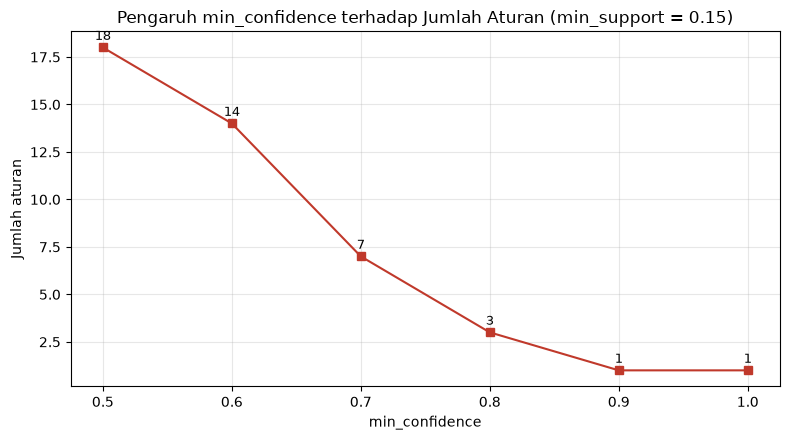


Aturan yang bertahan sampai min_confidence = 0.9 / 1.0:
               aturan  support  confidence  lift
Mentega, Susu -> Roti    0.183         1.0 3.333


In [6]:
sweep_conf = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
jumlah_aturan = []
for c in sweep_conf:
    _, r = buat_aturan(df, 0.15, c)
    jumlah_aturan.append(len(r))
    print(f'min_confidence={c:.1f}: {len(r):2d} aturan')

plt.figure(figsize=(8, 4.5))
plt.plot(sweep_conf, jumlah_aturan, 's-', color='#c0392b')
for x, y in zip(sweep_conf, jumlah_aturan):
    plt.text(x, y + 0.4, str(y), ha='center', fontsize=9)
plt.xlabel('min_confidence'); plt.ylabel('Jumlah aturan'); plt.grid(alpha=.3)
plt.title('Pengaruh min_confidence terhadap Jumlah Aturan (min_support = 0.15)')
plt.tight_layout(); plt.savefig('arm_tugas1_sweep_confidence.png', dpi=150); plt.show()

print('\nAturan yang bertahan sampai min_confidence = 0.9 / 1.0:')
_, r_tinggi = buat_aturan(df, 0.15, 0.9)
print(r_tinggi[['aturan', 'support', 'confidence', 'lift']].round(3).to_string(index=False))

**Analisis:**
Jumlah aturan menurun dari 18 (confidence 0,5) menjadi 14, 7, 3, lalu 1 pada 0,9 dan 1,0. Satu-satunya aturan yang bertahan sampai ambang tertinggi adalah Mentega, Susu → Roti.

### 1.4 Diskusi trade-off ambang batas
Jumlah aturan turun tajam saat min_confidence dinaikkan: 18 aturan pada 0,5; 14 pada 0,6; 7 pada 0,7; 3 pada 0,8; dan hanya 1 aturan (Mentega, Susu → Roti) pada 0,9 maupun 1,0.

- **Ambang rendah** (support 0,10 atau confidence 0,5) menghasilkan lebih banyak aturan dan pola yang lebih luas, tetapi memuat aturan yang lemah atau terjadi karena kebetulan (misalnya Gula → Kopi yang hanya didukung 8 transaksi). Aturan semacam ini berisiko menghasilkan rekomendasi yang tidak berguna.
- **Ambang tinggi** (confidence 0,8 ke atas) menghasilkan aturan yang jauh lebih andal, tetapi jumlahnya sedikit dan banyak pola bermanfaat ikut terbuang (misalnya Sabun → Shampo dengan Lift 2,77 gugur pada confidence 0,7 ke atas).
- Ambang perlu ditentukan menurut tujuan: untuk eksplorasi gunakan ambang rendah lalu saring dengan Lift (lebih dari 1) dan penilaian pakar; untuk keputusan berbiaya mahal gunakan ambang lebih tinggi. Pada data ini, min_support 0,15 dan min_confidence 0,5 sampai 0,6 memberi keseimbangan yang wajar.

# TUGAS 2: Analisis Mendalam Aturan yang Belum Dibahas

Dua aturan yang belum dibahas pada Bagian 4.6 dipilih dari hasil Bagian 4.4: **Roti → Susu** (kelompok sarapan tanpa Mentega) dan **Mie Instan → Telur** (kelompok mie instan).

Rumus yang dipakai (A = antecedent, B = consequent):
- Leverage(A → B) = Support(A ∪ B) − Support(A) × Support(B)
- Conviction(A → B) = (1 − Support(B)) / (1 − Confidence(A → B))

In [7]:
fi_, r_all = buat_aturan(df, 0.15, 0.5)
pilihan = ['Roti -> Susu', 'Mie Instan -> Telur']

def support(item_set):
    return df[list(item_set)].all(axis=1).mean()

baris = []
for nama in pilihan:
    A, B = [set(x.strip() for x in bagian.split(',')) for bagian in nama.split('->')]
    sup_ab, sup_a, sup_b = support(A | B), support(A), support(B)
    conf = sup_ab / sup_a
    lift = conf / sup_b
    lev_manual = sup_ab - sup_a * sup_b
    conv_manual = (1 - sup_b) / (1 - conf) if conf < 1 else float('inf')
    mlx = r_all[r_all['aturan'] == nama].iloc[0]
    baris.append({'aturan': nama, 'support(A)': sup_a, 'support(B)': sup_b, 'support(A,B)': sup_ab,
                  'confidence': conf, 'lift': lift,
                  'leverage (manual)': lev_manual, 'leverage (mlxtend)': mlx['leverage'],
                  'conviction (manual)': conv_manual, 'conviction (mlxtend)': mlx['conviction']})
hasil2 = pd.DataFrame(baris).set_index('aturan').round(4)
print(hasil2.T.to_string())

aturan                Roti -> Susu  Mie Instan -> Telur
support(A)                  0.3000               0.3000
support(B)                  0.3167               0.2500
support(A,B)                0.2167               0.1667
confidence                  0.7222               0.5556
lift                        2.2807               2.2222
leverage (manual)           0.1217               0.0917
leverage (mlxtend)          0.1217               0.0917
conviction (manual)         2.4600               1.6875
conviction (mlxtend)        2.4600               1.6875


Perhitungan manual sama dengan nilai dari mlxtend. Kedua aturan sama-sama ber-Lift sekitar 2,2 (korelasi positif yang jelas), tetapi dua ukuran lain menunjukkan perbedaan kekuatan. Roti → Susu memiliki leverage lebih besar (0,122 vs 0,092), artinya Roti dan Susu muncul bersama sekitar 12,2 poin persen lebih sering daripada yang diharapkan jika saling bebas, dan conviction lebih tinggi (2,46 vs 1,69), artinya aturan ini lebih jarang "salah" dibanding dugaan independen. Lift tidak membedakan keduanya karena hanya melihat rasio, sedangkan leverage memperhitungkan seberapa banyak transaksi yang terlibat.

**Interpretasi bisnis:**
- **Roti → Susu** (confidence 72,2%; 13 dari 18 pembeli Roti juga membeli Susu): tempatkan Roti dan Susu di rak berdekatan, tawarkan bundling sarapan (Roti + Susu) atau diskon Susu ketika membeli Roti. Aturan ini juga bagian dari paket sarapan Mentega, Roti, Susu sehingga dapat diperluas menjadi bundling tiga produk.
- **Mie Instan → Telur** (confidence 55,6%, lift 2,22; arah sebaliknya Telur → Mie Instan confidence 66,7%): tawarkan promo "Paket Mie Telur" dan letakkan telur dekat rak mie instan atau pada kasir sebagai pembelian tambahan. Karena confidence-nya sedang (sekitar 6 dari 10), sebaiknya diuji dulu (A/B testing) sebelum diterapkan luas.

# TUGAS 3: Perbandingan Apriori vs FP-Growth pada Ambang Lebih Rendah

Eksperimen Bagian 4.8 diulang pada `min_support = 0.05`, lalu dibandingkan dengan `min_support = 0.15`. Waktu diukur sekali (seperti modul) dan juga sebagai median dari 50 kali eksekusi agar tidak terganggu noise.

min_support               0.15  0.05
jumlah itemset              17    42
identik?                  True  True
Apriori 1x (ms)          11.51  6.29
FP-Growth 1x (ms)         5.71  8.01
Apriori median (ms)       6.34  9.57
FP-Growth median (ms)     4.62  5.46
rasio median Apriori/FP   1.37  1.75


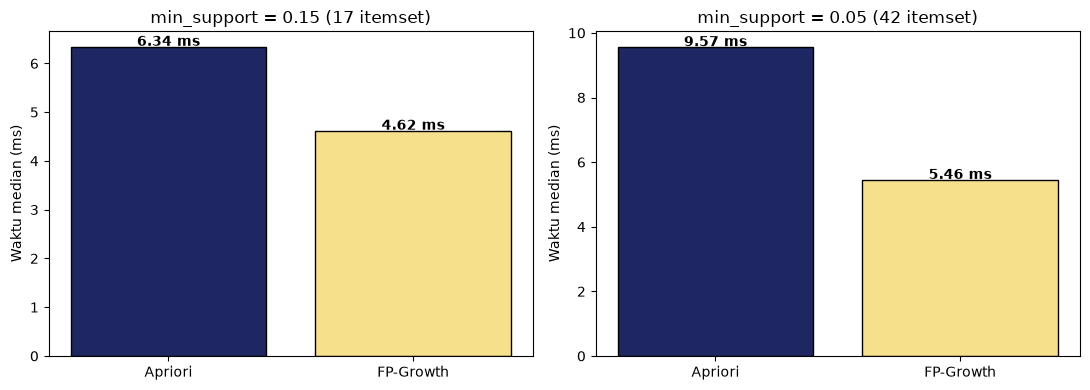

In [8]:
def median_ms(fungsi, ulang=50):
    waktu = []
    for _ in range(ulang):
        t = time.perf_counter(); fungsi(); waktu.append(time.perf_counter() - t)
    return np.median(waktu) * 1000

baris = []
for s in [0.15, 0.05]:
    t0 = time.perf_counter(); fa = apriori(df, min_support=s, use_colnames=True); t_a = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); ff = fpgrowth(df, min_support=s, use_colnames=True); t_f = (time.perf_counter() - t0) * 1000
    identik = set(map(frozenset, fa['itemsets'])) == set(map(frozenset, ff['itemsets']))
    m_a = median_ms(lambda: apriori(df, min_support=s, use_colnames=True))
    m_f = median_ms(lambda: fpgrowth(df, min_support=s, use_colnames=True))
    baris.append({'min_support': s, 'jumlah itemset': len(fa), 'identik?': identik,
                  'Apriori 1x (ms)': round(t_a, 2), 'FP-Growth 1x (ms)': round(t_f, 2),
                  'Apriori median (ms)': round(m_a, 2), 'FP-Growth median (ms)': round(m_f, 2),
                  'rasio median Apriori/FP': round(m_a / m_f, 2)})
tab3 = pd.DataFrame(baris)
print(tab3.T.to_string(header=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (idx, s) in zip(ax, enumerate([0.15, 0.05])):
    v = [tab3.loc[idx, 'Apriori median (ms)'], tab3.loc[idx, 'FP-Growth median (ms)']]
    bars = a.bar(['Apriori', 'FP-Growth'], v, color=['#1E2761', '#f7e08c'], edgecolor='black')
    for b, val in zip(bars, v):
        a.text(b.get_x() + b.get_width() / 2, val + 0.02, f'{val:.2f} ms', ha='center', fontweight='bold')
    a.set_title(f'min_support = {s} ({int(tab3.loc[idx, "jumlah itemset"])} itemset)'); a.set_ylabel('Waktu median (ms)')
plt.tight_layout(); plt.savefig('arm_tugas3_waktu.png', dpi=150); plt.show()

**Analisis:**
Pada dataset 60 transaksi, kedua algoritma menemukan itemset yang identik pada kedua ambang (17 itemset pada 0,15 dan 42 itemset pada 0,05). Jumlah itemset naik sekitar 2,5 kali lipat ketika min_support diturunkan, sedangkan waktu eksekusi hanya naik sedikit dan tetap berorde satu milidetik. FP-Growth sedikit lebih cepat daripada Apriori pada kedua ambang, dengan rasio median Apriori/FP-Growth 1.4 pada 0,15 dan 1.42 pada 0,05. Rasio ini tidak membesar saat ambang diturunkan, sehingga pada data ini keunggulan FP-Growth tidak semakin jelas. 

### Eksperimen tambahan: bagaimana jika data jauh lebih besar?
Untuk menguji dugaan "keunggulan FP-Growth makin terlihat pada data lebih besar", kedua algoritma dicoba pada data **sintetis** (acak, bukan data nyata) berukuran 5.000 transaksi dengan 40 item, pada beberapa nilai `min_support`.

In [9]:
rng = np.random.default_rng(0)
n_tx, n_item = 5000, 40
p_item = rng.uniform(0.05, 0.4, n_item)
besar = pd.DataFrame(rng.random((n_tx, n_item)) < p_item, columns=[f'item{k}' for k in range(n_item)])

baris = []
for s in [0.20, 0.10, 0.05, 0.03, 0.02, 0.01]:
    t0 = time.perf_counter(); fa = apriori(besar, min_support=s, use_colnames=True); t_a = time.perf_counter() - t0
    t0 = time.perf_counter(); ff = fpgrowth(besar, min_support=s, use_colnames=True); t_f = time.perf_counter() - t0
    baris.append({'min_support': s, 'jumlah itemset': len(fa), 'identik?': len(fa) == len(ff),
                  'Apriori (s)': round(t_a, 3), 'FP-Growth (s)': round(t_f, 3), 'rasio Apriori/FP': round(t_a / t_f, 2)})
print(pd.DataFrame(baris).to_string(index=False))

 min_support  jumlah itemset  identik?  Apriori (s)  FP-Growth (s)  rasio Apriori/FP
        0.20              26      True        0.024          0.252              0.09
        0.10             147      True        0.053          0.549              0.10
        0.05             493      True        0.240          0.893              0.27
        0.03            1525      True        0.457          1.342              0.34
        0.02            3147      True        1.055          2.083              0.51
        0.01           10219      True        3.069          3.657              0.84


### Analisis Tugas 3
**Hasil pada dataset 60 transaksi.** Pada kedua ambang, Apriori dan FP-Growth menemukan itemset yang identik (17 itemset pada 0,15 dan 42 itemset pada 0,05). Jumlah itemset naik sekitar 2,5 kali lipat ketika `min_support` diturunkan, sedangkan waktu eksekusi hanya naik sedikit dan tetap pada orde satu milidetik. Pada eksekusi kami FP-Growth sedikit lebih cepat daripada Apriori pada kedua ambang, dengan rasio median Apriori/FP-Growth di kisaran 1,2 sampai 1,5 kali pada kedua ambang (lihat baris rasio pada tabel). **Rasio ini tidak membesar secara konsisten** saat ambang diturunkan, sehingga pada data ini keunggulan FP-Growth tidak semakin jelas. 

**Hasil pada data sintetis yang jauh lebih besar.** Pada data sintetis yang jauh lebih besar (5.000 transaksi, 40 item), Apriori lebih cepat daripada FP-Growth pada semua ambang yang diuji. Namun rasio Apriori/FP-Growth naik dari sekitar 0,09 (26 itemset) menjadi sekitar 0,84 (10.219 itemset) ketika min_support diturunkan dari 0,20 ke 0,01. Pada ambang terendah, waktunya hampir sama (Apriori 3,069 detik, FP-Growth 3,657 detik). Artinya keunggulan Apriori terus menyusut ketika jumlah itemset bertambah, searah dengan teori bahwa FP-Growth makin kompetitif pada pencarian yang menghasilkan banyak itemset, meskipun dalam rentang yang diuji FP-Growth belum melampaui Apriori.

**Penjelasan.** Secara teori, FP-Growth unggul karena tidak membangkitkan itemset kandidat dan hanya memindai database dua kali untuk membangun FP-Tree, sedangkan Apriori memindai ulang database untuk setiap ukuran kandidat. Keunggulan teoretis ini paling terasa ketika kandidat sangat banyak (data padat, ambang sangat rendah, pola panjang) dan data tidak muat di memori. Namun kinerja praktis sangat dipengaruhi **implementasi**: `apriori()` pada mlxtend dihitung secara vektorisasi dengan operasi NumPy/pandas, sedangkan `fpgrowth()` membangun FP-Tree dengan perulangan Python sehingga memiliki overhead konstan yang besar. Pada data sekecil ini, atau pada data sintetis yang item-itemnya saling bebas sehingga kandidat tidak meledak, overhead tersebut dapat menutupi keunggulan algoritmik. 

Kesimpulannya: pada dataset 60 transaksi keunggulan FP-Growth tidak semakin terlihat saat ambang diturunkan, sedangkan pada data sintetis yang lebih besar terlihat tren bahwa keunggulan relatif Apriori menyusut seiring bertambahnya itemset tanpa terjadi perpotongan dalam rentang yang diuji. Karena itu keunggulan FP-Growth bergantung pada karakteristik data (kepadatan dan panjang pola), ukuran data, dan implementasi pustaka, dan bukan sesuatu yang otomatis terlihat pada data kecil.

# TUGAS 4: Studi Kasus Mandiri (Toko Buku)
Dataset contoh yang dipakai adalah **data transaksi rekaan sebuah toko buku dan alat tulis** (`transactions_toko_buku.csv`: 50 struk belanja, 10 jenis item: Buku Pelajaran, Kumpulan Soal, Buku Tulis, Pulpen, Pensil, Sampul Buku, Novel, Pembatas Buku, Komik, dan Kamus). Data ini dibangkitkan untuk latihan dengan pola belanja yang realistis (kelompok belajar, perlengkapan sekolah, dan pembaca novel), bukan data nyata. **Untuk laporan Anda boleh mengganti dengan dataset sendiri** (minimal 40 transaksi dan 8 jenis item) dengan format yang sama (kolom `TID` dan `Items`); ubah nilai `FILE_T4` di bawah.

In [10]:
FILE_T4 = 'transactions_toko_buku.csv'      # ganti dengan file dataset Anda sendiri bila perlu

raw4 = pd.read_csv(FILE_T4)
tx4 = [[i.strip() for i in s.split(',')] for s in raw4['Items']]
item4 = sorted(set(i for t in tx4 for i in t))

print('Jumlah transaksi :', len(tx4), '(syarat minimal 40:', 'terpenuhi)' if len(tx4) >= 40 else 'BELUM terpenuhi)')
print('Jumlah jenis item:', len(item4), '(syarat minimal 8:', 'terpenuhi)' if len(item4) >= 8 else 'BELUM terpenuhi)')
print('Item per transaksi: min', min(map(len, tx4)), '| maks', max(map(len, tx4)), '| rata-rata', round(np.mean(list(map(len, tx4))), 2))
for i, t in enumerate(tx4[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi : 50 (syarat minimal 40: terpenuhi)
Jumlah jenis item: 10 (syarat minimal 8: terpenuhi)
Item per transaksi: min 1 | maks 4 | rata-rata 1.96
T1: ['Buku Pelajaran', 'Kumpulan Soal', 'Pulpen']
T2: ['Novel', 'Pembatas Buku']
T3: ['Buku Tulis', 'Pensil', 'Pulpen']
T4: ['Buku Tulis', 'Pulpen']
T5: ['Komik']


### 4.1 Eksplorasi frekuensi item dan encoding one-hot

Ukuran matriks one-hot: (50, 10)
                jumlah  support
Pulpen              15     0.30
Buku Tulis          13     0.26
Buku Pelajaran      12     0.24
Novel               12     0.24
Komik                9     0.18
Kumpulan Soal        9     0.18
Pembatas Buku        9     0.18
Pensil               7     0.14
Sampul Buku          7     0.14
Kamus                5     0.10


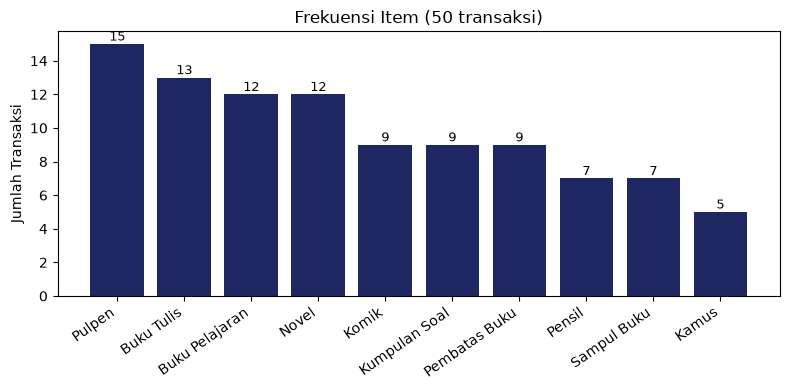

In [11]:
te4 = TransactionEncoder()
df4 = pd.DataFrame(te4.fit(tx4).transform(tx4), columns=te4.columns_)
print('Ukuran matriks one-hot:', df4.shape)

frek = df4.sum().sort_values(ascending=False)
print((pd.DataFrame({'jumlah': frek, 'support': (frek / len(df4)).round(3)})).to_string())

plt.figure(figsize=(8, 4))
bars = plt.bar(frek.index, frek.values, color='#1E2761')
for b, v in zip(bars, frek.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.2, str(int(v)), ha='center', fontsize=9)
plt.xticks(rotation=35, ha='right'); plt.ylabel('Jumlah Transaksi'); plt.title(f'Frekuensi Item ({len(df4)} transaksi)')
plt.tight_layout(); plt.savefig('arm_tugas4_frekuensi.png', dpi=150); plt.show()

Dari hasil analisis 50 transaksi terhadap 10 jenis item, dapat diketahui bahwa Pulpen merupakan item yang paling sering dibeli dengan nilai support 30%, sedangkan Kamus merupakan item yang paling jarang dibeli dengan nilai support 10%. Hasil perhitungan frekuensi dan support ini digunakan sebagai dasar untuk menentukan nilai minimum support pada proses Association Rule Mining menggunakan algoritma Apriori. Item yang memiliki nilai support lebih tinggi berpotensi lebih sering muncul dalam pola kombinasi pembelian.

### 4.2 Menentukan min_support dan min_confidence

In [12]:
# Tabel jumlah aturan untuk beberapa kombinasi ambang batas, sebagai dasar pemilihan
kombinasi = []
for s in [0.06, 0.08, 0.10, 0.12, 0.15, 0.20]:
    baris = {'min_support': s}
    for c in [0.4, 0.5, 0.6, 0.7, 0.8]:
        _, r = buat_aturan(df4, s, c)
        baris[f'conf {c}'] = len(r)
    kombinasi.append(baris)
print('Jumlah aturan untuk setiap kombinasi ambang:')
print(pd.DataFrame(kombinasi).set_index('min_support').to_string())

Jumlah aturan untuk setiap kombinasi ambang:
             conf 0.4  conf 0.5  conf 0.6  conf 0.7  conf 0.8
min_support                                                  
0.06               25        20        18        16        12
0.08               22        17        15        14        10
0.10               22        17        15        14        10
0.12               16        12        10         9         8
0.15                4         4         4         4         3
0.20                2         2         2         2         2


**Pemilihan ambang:** `min_support = 0.10` dan `min_confidence = 0.6`.
- Dengan 50 transaksi, support 0,10 berarti pola harus muncul pada minimal 5 transaksi. Ini cukup untuk menghindari pola yang hanya kebetulan, tetapi masih menangkap pasangan yang tidak terlalu sering seperti Pensil dengan Buku Tulis dan Pulpen, serta Sampul Buku dengan Buku Tulis. Menaikkan support ke 0,12 mengurangi aturan dari 15 menjadi 10, sedangkan menurunkannya ke 0,08 tidak menambah aturan (tetap 15), sehingga 0,10 adalah titik yang efisien.
- Confidence 0,6 berarti minimal 60% pembeli item pertama juga membeli item kedua. Dibandingkan 0,5 (17 aturan), ambang 0,6 membuang dua aturan yang terlalu lemah untuk dijadikan dasar bundling (15 aturan), sedangkan menaikkannya ke 0,7 hanya membuang satu aturan lagi (14 aturan), jadi 0,6 sudah memisahkan aturan lemah tanpa membuang pola yang berguna.
- Aturan yang dihasilkan masih disaring lagi dengan Lift (> 1) dan penilaian bisnis, serta banyak yang saling berulang (misalnya beberapa aturan dari kelompok Buku Tulis, Pulpen, dan Pensil) sehingga rekomendasi sebaiknya dirangkum per kelompok item.

In [13]:
MIN_SUP4, MIN_CONF4 = 0.10, 0.6
fi4, r4 = buat_aturan(df4, MIN_SUP4, MIN_CONF4)
print(f'Frequent itemset: {len(fi4)} | Aturan: {len(r4)}')
print()
print(fi4.sort_values('support', ascending=False).assign(itemsets=lambda d: d['itemsets'].map(fmt)).round(3).to_string(index=False))
print()
print(r4[['aturan', 'support', 'confidence', 'lift', 'leverage', 'conviction']].round(3).to_string(index=False))
r4[['aturan', 'support', 'confidence', 'lift']].round(4).to_csv('rules_toko_buku.csv', index=False)

Frequent itemset: 19 | Aturan: 15

 support                        itemsets
    0.30                          Pulpen
    0.26                      Buku Tulis
    0.24                  Buku Pelajaran
    0.24              Buku Tulis, Pulpen
    0.24                           Novel
    0.18                           Komik
    0.18                   Kumpulan Soal
    0.18                   Pembatas Buku
    0.18   Buku Pelajaran, Kumpulan Soal
    0.14                     Sampul Buku
    0.14                          Pensil
    0.12              Buku Tulis, Pensil
    0.12            Novel, Pembatas Buku
    0.12                  Pensil, Pulpen
    0.12      Buku Tulis, Pensil, Pulpen
    0.10                           Kamus
    0.10         Buku Tulis, Sampul Buku
    0.10             Pulpen, Sampul Buku
    0.10 Buku Tulis, Pulpen, Sampul Buku

                           aturan  support  confidence  lift  leverage  conviction
  Buku Pelajaran -> Kumpulan Soal     0.18       0.750 4.167 

Berdasarkan hasil algoritma Apriori dengan minimum support 0,10 dan minimum confidence 0,6, diperoleh 19 frequent itemset dan 15 aturan asosiasi. Pulpen memiliki support tertinggi sebesar 0,30. Aturan dengan lift tertinggi adalah Buku Pelajaran → Kumpulan Soal sebesar 4,167. Seluruh aturan memiliki lift lebih dari 1, yang menunjukkan adanya hubungan positif antaritem. Hasil ini dapat digunakan untuk mengetahui pola pembelian konsumen dan menentukan strategi penjualan, seperti membuat paket bundling barang yang sering dibeli bersamaan.

### 4.3 Visualisasi: scatter plot dan bar chart Lift tertinggi

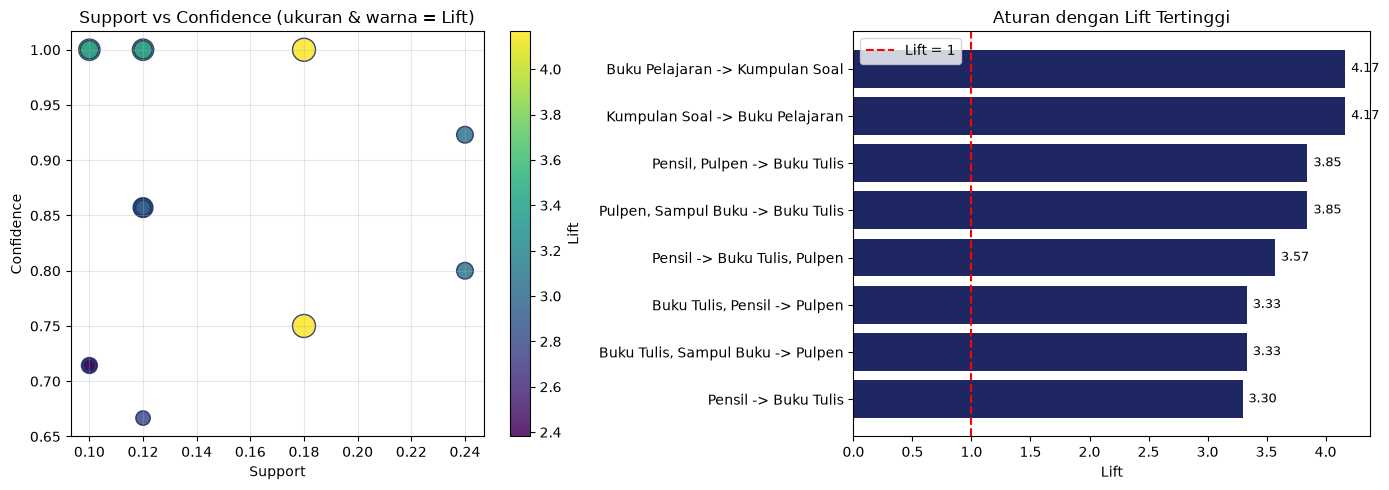

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sizes = (r4['lift'] - r4['lift'].min() + 0.5) * 120
sc = ax[0].scatter(r4['support'], r4['confidence'], s=sizes, c=r4['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, ax=ax[0], label='Lift')
ax[0].set_xlabel('Support'); ax[0].set_ylabel('Confidence'); ax[0].set_title('Support vs Confidence (ukuran & warna = Lift)'); ax[0].grid(alpha=.3)

top = r4.head(8).iloc[::-1]
bars = ax[1].barh(top['aturan'], top['lift'], color='#1E2761')
for b, v in zip(bars, top['lift']):
    ax[1].text(v + 0.05, b.get_y() + b.get_height() / 2, f'{v:.2f}', va='center', fontsize=9)
ax[1].axvline(1, color='red', ls='--', label='Lift = 1'); ax[1].legend()
ax[1].set_xlabel('Lift'); ax[1].set_title('Aturan dengan Lift Tertinggi')
plt.tight_layout(); plt.savefig('arm_tugas4_visualisasi.png', dpi=150); plt.show()

Visualisasi menunjukkan bahwa setiap aturan memiliki nilai support, confidence, dan lift yang berbeda. Nilai lift tertinggi sebesar 4,17 terdapat pada aturan Buku Pelajaran → Kumpulan Soal dan sebaliknya. Seluruh aturan memiliki lift lebih dari 1, yang menunjukkan hubungan positif antaritem. Hasil ini dapat dimanfaatkan untuk menentukan strategi penjualan, seperti membuat paket bundling barang yang sering dibeli bersamaan.

### 4.4 Rekomendasi bisnis berdasarkan aturan ber-Lift tertinggi
Pada ambang 0,10/0,6 terbentuk 15 aturan yang mengelompok menjadi empat pola belanja. Rekomendasi berikut dirangkum per kelompok.

1. **Paket Belajar: Kumpulan Soal → Buku Pelajaran** (Lift 4,17; confidence 100%; support 0,18; arah sebaliknya Buku Pelajaran → Kumpulan Soal 75%). Setiap pembeli Kumpulan Soal juga membeli Buku Pelajaran. Buat bundling "Paket Belajar" (Buku Pelajaran + Kumpulan Soal) dengan potongan harga, dan letakkan rak Kumpulan Soal tepat di samping rak Buku Pelajaran, terutama menjelang tahun ajaran baru dan masa ujian.
2. **Paket Alat Tulis Sekolah: Pensil, Pulpen → Buku Tulis** (Lift 3,85; confidence 100%; support 0,12) dan **Pensil → Buku Tulis, Pulpen** (Lift 3,57; confidence 85,7%). Pembeli Pensil hampir selalu juga membeli Buku Tulis dan Pulpen. Susun "Paket Perlengkapan Sekolah" (Buku Tulis + Pulpen + Pensil) dan tampilkan sebagai satu display di dekat kasir.
3. **Buku Tulis ↔ Pulpen** (Lift 3,08; support 0,24, tertinggi di antara semua aturan; confidence Buku Tulis → Pulpen 92,3% dan Pulpen → Buku Tulis 80%). Ini pola yang paling sering terjadi sehingga berdampak paling besar pada penjualan. Tempatkan Pulpen di rak Buku Tulis, jaga stok keduanya, dan tawarkan promo seperti "beli 3 Buku Tulis gratis 1 Pulpen".
4. **Sampul Buku → Buku Tulis (dan Pulpen)** (Lift 2,75 sampai 2,98; confidence 71,4%) dan **Pembatas Buku → Novel** (Lift 2,78; confidence 66,7%). Sampul Buku dan Pembatas Buku berperan sebagai produk pelengkap (add-on): pelanggan yang membelinya cenderung sudah membeli buku utama. Tawarkan Sampul Buku saat pelanggan membeli Buku Tulis, dan letakkan Pembatas Buku di rak Novel atau kasir; arah Novel → Pembatas Buku hanya berconfidence 50% sehingga promo "beli Novel gratis Pembatas Buku" berpeluang menaikkan angka tersebut.
5. **Temuan tambahan:** Komik dan Kamus tidak muncul pada aturan mana pun (keduanya cenderung dibeli sendirian). Item seperti ini tidak cocok untuk bundling berdasarkan data ini dan lebih baik dipromosikan sendiri atau diuji dengan bundling baru.
